# Notebook 01: ETL (ingestão, diagnóstico, tratamento e qualidade)

**Trabalho N3, Análise Preditiva (Católica SC).** Pipeline MLOps sobre o dataset Spambase (UCI, id 94, licença CC BY 4.0): 4.601 e-mails, 57 features numéricas e o alvo `spam` (1 = spam, 0 = não spam).

Este é o primeiro dos quatro notebooks do ciclo. Ele simula a **chegada de dados novos**: a cada ciclo incorpora o próximo lote ainda não ingerido, diagnostica os dados, trata o que for necessário, verifica a qualidade e grava o treino do ciclo.

| | Arquivos |
|---|---|
| **Lê** | `config/config.yaml`, `models/estado_ingestao.json`, `data/raw/lotes/lote_*.csv`, `data/raw/spambase.csv` (só o cabeçalho, para conferir o schema) |
| **Grava** | `data/processed/treino_<data_version>.csv`, `artifacts/ciclo_atual.json`, `reports/figuras/<cycle_id>_01_*.csv` e `.png` |

**Sobre vazamento de dados.** Este notebook **não lê o teste fixo** (`data/raw/teste_fixo.csv`). Além disso, nenhum tratamento aqui calcula estatísticas que o modelo vai usar depois (não há imputação pela média, nem escalonamento, nem seleção de features). Tudo o que depende dos dados para ser ajustado (padronização e seleção) fica dentro do `Pipeline` do scikit-learn, nos notebooks 02 e 03, e é ajustado só no treino de cada fold.

## 0. Preparação do ambiente

Esta célula faz o mesmo notebook rodar sem alterações no **Google Colab**, no **GitHub Actions** e **localmente**:

* **No Colab** (`'google.colab' in sys.modules`): clona o repositório definido em `REPO_URL` dentro de `/content`, entra na pasta e instala o `requirements.txt`. Se o repositório já estiver clonado, só atualiza com `git pull`. Se a instalação trocar a versão de uma biblioteca que o Colab já tinha carregado, a sessão é reiniciada automaticamente: basta executar esta célula de novo.
* **Fora do Colab**: procura a raiz do repositório (a pasta que contém `config/config.yaml`) subindo a partir da pasta atual e muda o diretório de trabalho para ela.

Nos dois casos a raiz entra no `sys.path`, o que permite `from src... import ...`. Todos os caminhos usados depois são relativos à raiz.

**`REPO_URL` já aponta para o repositório do projeto (`https://github.com/eduardaramalho/n3-analise-preditiva.git`). Só altere se o repositório mudar de endereço.**

In [1]:
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/eduardaramalho/n3-analise-preditiva.git"  # repositório do projeto
REPO_BRANCH = "main"

NA_COLAB = "google.colab" in sys.modules

if NA_COLAB:
    pasta_repo = Path("/content") / Path(REPO_URL).stem
    if not (pasta_repo / ".git").exists():
        subprocess.run(["git", "clone", "-b", REPO_BRANCH, REPO_URL, str(pasta_repo)], check=True)
    else:
        subprocess.run(["git", "-C", str(pasta_repo), "pull", "--ff-only"], check=False)
    os.chdir(pasta_repo)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
    # Se o pip trocou a versão de uma biblioteca já carregada, a sessão precisa reiniciar
    from importlib.metadata import version
    trocadas = [m for m, dist in {"numpy": "numpy", "pandas": "pandas", "sklearn": "scikit-learn",
                                  "matplotlib": "matplotlib"}.items()
                if m in sys.modules and getattr(sys.modules[m], "__version__", version(dist)) != version(dist)]
    if trocadas:
        print(f"Versões atualizadas ({', '.join(trocadas)}). Reiniciando a sessão: execute esta célula de novo.")
        os.kill(os.getpid(), 9)
else:
    raiz = Path.cwd().resolve()
    while not (raiz / "config" / "config.yaml").exists():
        if raiz.parent == raiz:
            raise FileNotFoundError("Raiz do repositório não encontrada (config/config.yaml).")
        raiz = raiz.parent
    os.chdir(raiz)

RAIZ = Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))
print("Ambiente:", "Google Colab" if NA_COLAB else "local / GitHub Actions")
print("Raiz do repositório:", RAIZ)

Ambiente: local / GitHub Actions
Raiz do repositório: /home/user/n3-analise-preditiva


## 1. Configuração

Todos os parâmetros vêm de `config/config.yaml`. A seed 42 é fixada para que qualquer sorteio seja reprodutível.

A variável `RESETAR` serve só para testes no Colab: com `True`, apaga o estado do pipeline (lotes ingeridos, modelo vigente, MLflow, figuras) e o ciclo recomeça do lote 1. **Deixe sempre `False`** no repositório, porque o GitHub Actions executa este mesmo notebook.

In [2]:
import pandas as pd
from IPython.display import display

from src.utils import carregar_config, caminho, fixar_seed
from src import ingestao, preprocessamento as prep, graficos
from src.resetar_estado import resetar

cfg = carregar_config()
SEED = cfg["projeto"]["seed"]
fixar_seed(SEED)
graficos.aplicar_estilo()
pd.set_option("display.max_columns", 30)

RESETAR = False   # True apenas para recomeçar os ciclos do zero em testes
if RESETAR:
    print("Estado apagado:", resetar(confirmar=True))

ALVO, COL_ID = cfg["dados"]["alvo"], cfg["dados"]["coluna_id"]
print("Seed:", SEED, "| alvo:", ALVO, "| identificador:", COL_ID)

Seed: 42 | alvo: spam | identificador: id_email


## 2. Planejamento do ciclo: qual lote entra agora?

O arquivo `models/estado_ingestao.json` guarda os lotes já incorporados em ciclos anteriores. A regra é:

* **Ciclo 1:** nenhum lote ingerido, então entra o `lote_01` (60% dos e-mails).
* **Ciclo 2:** o `lote_01` já foi ingerido, então o treino passa a ser `lote_01` + `lote_02`.
* **Ciclos seguintes:** não há lote novo. O treino é o mesmo, mas a votação de features e a competição de modelos são refeitas. Isso mostra que o pipeline continua estável sem dados novos.

O `cycle_id` é a data e hora UTC do início do ciclo (ex.: `20261117T230512Z`). Ele aparece em todos os arquivos, runs do MLflow e figuras deste ciclo.

O estado de ingestão só é atualizado no **fim** do notebook 04. Se qualquer notebook falhar no meio, o lote não é marcado como ingerido e o próximo ciclo tenta de novo.

In [3]:
estado = ingestao.carregar_estado(cfg)
plano = ingestao.planejar_ciclo(cfg)
CYCLE_ID = plano["cycle_id"]

print("Lotes disponíveis:      ", ingestao.listar_lotes(cfg))
print("Lotes já ingeridos:     ", plano["lotes_ja_ingeridos"])
print("Lote novo neste ciclo:  ", plano["lote_novo"] or "nenhum (ciclo sem dados novos)")
print("Lotes no treino:        ", plano["lotes_ciclo"])
print("cycle_id:               ", CYCLE_ID)

Lotes disponíveis:       ['lote_01', 'lote_02']
Lotes já ingeridos:      ['lote_01', 'lote_02']
Lote novo neste ciclo:   nenhum (ciclo sem dados novos)
Lotes no treino:         ['lote_01', 'lote_02']
cycle_id:                20261122T202358Z


## 3. Ingestão sem duplicar registros

Os lotes do ciclo são concatenados. Cada e-mail tem um identificador estável, `id_email` (a posição dele no arquivo original da UCI). Se um mesmo `id_email` aparecer duas vezes (por exemplo, um lote reenviado), só a primeira ocorrência fica. Assim o mesmo registro nunca entra duas vezes no treino.

A coluna auxiliar `lote_origem` registra de qual lote veio cada linha, para rastreabilidade. Ela não é usada como feature.

In [4]:
df_bruto, info_ingestao = ingestao.montar_treino(cfg, plano["lotes_ciclo"])
pd.Series(info_ingestao, name="valor").to_frame()

,valor
linhas_por_lote,"{'lote_01': 2796, 'lote_02': 900}"
linhas_concatenadas,3696
ids_repetidos_removidos,0
linhas_apos_ingestao,3696


## 4. Diagnóstico antes do tratamento

Para cada uma das 57 colunas calculamos:

* **tipo** e **não numéricos**: se alguma coluna veio como texto, a leitura está errada;
* **ausentes**: valores vazios;
* **fora da faixa**: a documentação do dataset define faixas válidas. `word_freq_*` e `char_freq_*` são percentuais, então ficam em [0, 100]. `capital_run_length_*` medem sequências de letras maiúsculas, então são no mínimo 1, e `longest` e `total` são inteiros;
* **outliers pela regra do IQR**: valores acima de Q3 + 1,5 x IQR (ou abaixo de Q1 - 1,5 x IQR). Serve só para **descrever** a distribuição, não para remover;
* **taxa de spam entre os outliers** da coluna: ajuda a decidir se outlier é erro ou informação.

No nível do conjunto, contamos também **duplicatas exatas** (as 57 features e o alvo iguais) e **rótulos conflitantes** (as 57 features iguais com alvos diferentes).

In [5]:
diag_antes, resumo_antes = prep.diagnosticar(df_bruto, cfg)
graficos.salvar_tabela(diag_antes, cfg, CYCLE_ID, "01_diagnostico_antes")
display(pd.Series(resumo_antes, name="antes").to_frame())
diag_antes.head(10)

,antes
linhas,3696
colunas_features,57
ausentes_total,0
colunas_nao_numericas,0
ids_duplicados,0
linhas_duplicadas_exatas,329
grupos_rotulo_conflitante,2
linhas_rotulo_conflitante,4
valores_fora_da_faixa,0
valores_alvo,"[0, 1]"


,coluna,tipo,ausentes,nao_numericos,fora_da_faixa,min,max,media,mediana,pct_zeros,q1,q3,limite_sup_iqr,outliers_iqr,pct_outliers,taxa_spam_outliers
0,word_freq_make,float64,0,0,0,0.0,4.00,0.0994,0.0,77.60,0.0,0.00,0.000,828,22.40,0.6051
1,word_freq_address,float64,0,0,0,0.0,14.28,0.2416,0.0,80.25,0.0,0.00,0.000,730,19.75,0.6767
2,word_freq_all,float64,0,0,0,0.0,4.54,0.2772,0.0,59.23,0.0,0.41,1.025,280,7.58,0.5393
3,word_freq_3d,float64,0,0,0,0.0,42.81,0.0649,0.0,99.05,0.0,0.00,0.000,35,0.95,0.8571
4,word_freq_our,float64,0,0,0,0.0,10.00,0.3069,0.0,62.34,0.0,0.39,0.975,394,10.66,0.7183
5,word_freq_over,float64,0,0,0,0.0,5.88,0.0960,0.0,78.68,0.0,0.00,0.000,788,21.32,0.6815
6,word_freq_remove,float64,0,0,0,0.0,7.27,0.1151,0.0,82.58,0.0,0.00,0.000,644,17.42,0.9472
7,word_freq_internet,float64,0,0,0,0.0,6.06,0.0992,0.0,82.49,0.0,0.00,0.000,647,17.51,0.7558
8,word_freq_order,float64,0,0,0,0.0,5.26,0.0884,0.0,83.41,0.0,0.00,0.000,613,16.59,0.7129
9,word_freq_mail,float64,0,0,0,0.0,18.18,0.2453,0.0,71.54,0.0,0.17,0.425,677,18.32,0.6145


## 5. Outliers: erro ou sinal de spam?

Nas frequências de palavras, a maioria dos e-mails tem valor zero (a palavra não aparece). Por isso Q1 e Q3 costumam ser 0, o IQR também é 0, e **qualquer valor diferente de zero vira "outlier"** pela regra do IQR. Remover esses valores apagaria justamente os e-mails em que a palavra aparece.

O gráfico abaixo mostra, para as colunas com mais outliers, a proporção de spam entre os e-mails marcados como outlier. A linha tracejada é a taxa geral de spam do treino. Quando a barra passa muito da linha (ex.: `char_freq_$`, `word_freq_free`, `word_freq_internet`), o outlier é um **forte indício de spam**. Quando fica muito abaixo (ex.: `word_freq_hp`, `word_freq_george`), indica e-mail legítimo. Nos dois casos é informação útil para o modelo.

**Decisão: manter todos os outliers.** Os modelos escolhidos lidam bem com eles: a Random Forest divide por limiares e não é afetada pela escala, e os modelos lineares recebem `StandardScaler` dentro do `Pipeline`.

,coluna,pct_zeros,q3,limite_sup_iqr,max,outliers_iqr,pct_outliers,taxa_spam_outliers
24,word_freq_hp,76.27,0.000,0.0000,20.830,877,23.73,0.0502
0,word_freq_make,77.60,0.000,0.0000,4.000,828,22.40,0.6051
17,word_freq_email,77.81,0.000,0.0000,7.690,820,22.19,0.6622
44,word_freq_re,71.65,0.110,0.2750,21.420,806,21.81,0.2928
5,word_freq_over,78.68,0.000,0.0000,5.880,788,21.32,0.6815
16,word_freq_business,79.71,0.000,0.0000,7.140,750,20.29,0.7200
15,word_freq_free,73.08,0.110,0.2750,20.000,747,20.21,0.8461
1,word_freq_address,80.25,0.000,0.0000,14.280,730,19.75,0.6767
9,word_freq_mail,71.54,0.170,0.4250,18.180,677,18.32,0.6145
12,word_freq_people,81.71,0.000,0.0000,5.550,676,18.29,0.6095


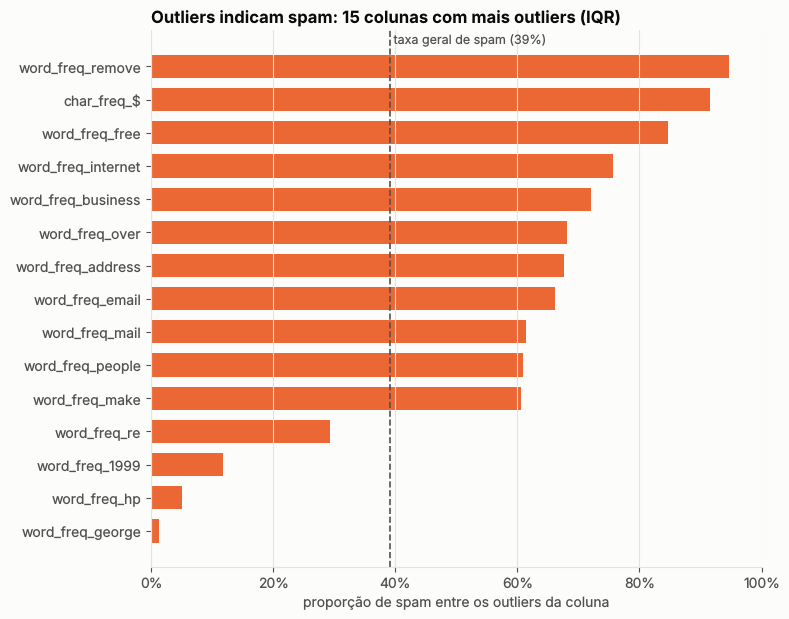

In [6]:
cols_outliers = ["coluna", "pct_zeros", "q3", "limite_sup_iqr", "max", "outliers_iqr", "pct_outliers", "taxa_spam_outliers"]
tabela_outliers = diag_antes[cols_outliers].sort_values("outliers_iqr", ascending=False)
graficos.salvar_tabela(tabela_outliers, cfg, CYCLE_ID, "01_outliers_iqr")

fig = graficos.grafico_spam_em_outliers(diag_antes, resumo_antes["proporcao_spam"])
graficos.salvar_figura(fig, cfg, CYCLE_ID, "01_outliers_taxa_spam")
tabela_outliers.head(15)

## 6. Tratamento

Os tratamentos são aplicados em ordem, e cada um registra quantas linhas removeu e por quê. Todas as regras são fixas (vêm da documentação do dataset), não dependem de estatísticas calculadas sobre os dados e por isso não geram vazamento.

1. **Identificador repetido:** o mesmo e-mail não entra duas vezes.
2. **Conversão de tipos:** tudo vira numérico. Texto inválido vira ausente.
3. **Alvo inválido:** só 0 e 1 são aceitos.
4. **Ausentes:** a linha é removida. Não imputamos porque imputar pela média ou mediana fora do `Pipeline` usaria informação de todo o conjunto, inclusive das linhas que depois serão validação em cada fold.
5. **Fora da faixa:** valor impossível pela definição da variável é erro de coleta.
6. **Rótulo conflitante:** e-mails idênticos com rótulos diferentes são contraditórios. Removemos todas as cópias.
7. **Duplicatas exatas:** mantemos só a primeira ocorrência. Cópias dão peso extra a poucos e-mails e, na validação cruzada, a mesma linha poderia cair no treino e na validação de um fold, inflando a métrica (é uma forma de vazamento).
8. **Outliers:** mantidos, como justificado na seção 5.

Observação: as duplicatas exatas entre treino e teste já foram evitadas na preparação dos lotes (`src/preparar_lotes.py`), que mantém cópias idênticas sempre do mesmo lado da divisão.

In [7]:
df_treino, log_tratamento = prep.tratar(df_bruto, cfg)
graficos.salvar_tabela(log_tratamento, cfg, CYCLE_ID, "01_tratamentos")
log_tratamento

,etapa,linhas_removidas,linhas_restantes,justificativa
0,1. Identificador repetido,0,3696,O mesmo e-mail (id_email) não pode entrar duas...
1,2. Conversão de tipos,0,3696,Todas as features convertidas para numérico; t...
2,3. Alvo inválido,0,3696,O alvo só pode ser 0 (não spam) ou 1 (spam). S...
3,4. Valores ausentes,0,3696,Remoção em vez de imputação: imputar exigiria ...
4,5. Fora da faixa documentada,0,3696,"Frequências devem estar em [0, 100] e contagen..."
5,6. Rótulo conflitante,4,3692,E-mails com as 57 features idênticas mas rótul...
6,7. Duplicatas exatas,329,3363,Cópias idênticas dão peso extra a poucos e-mai...
7,8. Outliers,0,3363,Mantidos. Em frequências de palavras e caracte...


## 7. Diagnóstico depois do tratamento

Mesmo diagnóstico da seção 4, agora no treino tratado. A tabela lado a lado mostra o efeito de cada tratamento no conjunto.

In [8]:
diag_depois, resumo_depois = prep.diagnosticar(df_treino, cfg)
graficos.salvar_tabela(diag_depois, cfg, CYCLE_ID, "01_diagnostico_depois")

comparativo = pd.DataFrame({"antes": resumo_antes, "depois": resumo_depois})
graficos.salvar_tabela(comparativo, cfg, CYCLE_ID, "01_resumo_antes_depois", index=True)
comparativo

,antes,depois
linhas,3696,3363
colunas_features,57,57
ausentes_total,0,0
colunas_nao_numericas,0,0
ids_duplicados,0,0
linhas_duplicadas_exatas,329,0
grupos_rotulo_conflitante,2,0
linhas_rotulo_conflitante,4,0
valores_fora_da_faixa,0,0
valores_alvo,"[0, 1]","[0, 1]"


## 8. Verificação automática de qualidade

Antes de liberar o treino para os próximos notebooks, um conjunto de regras é conferido. **Se qualquer regra falhar, a função levanta um erro**, a execução do notebook para e, no GitHub Actions, o pipeline inteiro para sem promover nenhum modelo.

O schema esperado é lido do cabeçalho do CSV original (`data/raw/spambase.csv`): os mesmos 57 nomes oficiais, na mesma ordem.

In [9]:
colunas_esperadas = [col for col in pd.read_csv(caminho(cfg["dados"]["bruto"]), nrows=0).columns if col != ALVO]
qualidade = prep.validar_qualidade(df_treino, cfg, colunas_esperadas)
graficos.salvar_tabela(qualidade, cfg, CYCLE_ID, "01_verificacao_qualidade")
print("Verificação de qualidade: APROVADA")
qualidade

Verificação de qualidade: APROVADA


,regra,aprovado
0,"Schema: colunas iguais às do dataset original,...",True
1,Quantidade de features = 57,True
2,Todas as features são numéricas,True
3,Alvo contém apenas 0 e 1,True
4,Alvo contém as duas classes,True
5,Sem valores ausentes,True
6,Sem valores fora da faixa documentada,True
7,Sem identificadores repetidos,True
8,Treino não vazio,True


## 9. Gravação do treino e dos identificadores do ciclo

* **`data_version`** identifica exatamente os dados de treino: os lotes incorporados mais um hash SHA-256 do conteúdo tratado (ex.: `lotes-01+02_h3f2a9c1b7d4e`). Se uma única célula mudar, o hash muda.
* O treino é salvo em `data/processed/treino_<data_version>.csv`. Como o nome depende do conteúdo, ciclos sem dados novos reaproveitam o mesmo arquivo em vez de criar cópias.
* **`artifacts/ciclo_atual.json`** é o "crachá" do ciclo: os notebooks 02, 03 e 04 leem dele o `cycle_id`, o `data_version` e o caminho do treino, garantindo que todos trabalham sobre os mesmos dados.

In [10]:
hash_ = ingestao.hash_treino(df_treino, COL_ID)
DATA_VERSION = ingestao.gerar_data_version(plano["lotes_ciclo"], hash_)

pasta_proc = caminho(cfg["dados"]["pasta_processados"])
pasta_proc.mkdir(parents=True, exist_ok=True)
arquivo_treino = f"{cfg['dados']['pasta_processados']}/treino_{DATA_VERSION}.csv"
df_treino.sort_values(COL_ID).to_csv(caminho(arquivo_treino), index=False)

ciclo = {
    "cycle_id": CYCLE_ID,
    "data_version": DATA_VERSION,
    "lotes_ciclo": plano["lotes_ciclo"],
    "lote_novo": plano["lote_novo"],
    "tem_dados_novos": plano["tem_dados_novos"],
    "arquivo_treino": arquivo_treino,
    "linhas_treino": len(df_treino),
    "proporcao_spam_treino": resumo_depois["proporcao_spam"],
    "etapas": {"01_etl": "concluido"},
}
ingestao.registrar_ciclo(cfg, ciclo)
pd.Series(ciclo, name="ciclo_atual").to_frame()

,ciclo_atual
cycle_id,20261122T202358Z
data_version,lotes-01+02_h0ce6906487cc
lotes_ciclo,"[lote_01, lote_02]"
lote_novo,None
tem_dados_novos,False
arquivo_treino,data/processed/treino_lotes-01+02_h0ce6906487c...
linhas_treino,3363
proporcao_spam_treino,0.3988
etapas,{'01_etl': 'concluido'}


## 10. Distribuição das classes

Comparação da quantidade de e-mails de cada classe antes e depois do tratamento. A proporção de spam deve mudar pouco: o tratamento remove principalmente cópias, não uma classe específica.

PosixPath('/home/user/n3-analise-preditiva/reports/figuras/20261122T202358Z_01_classes_antes_depois.png')

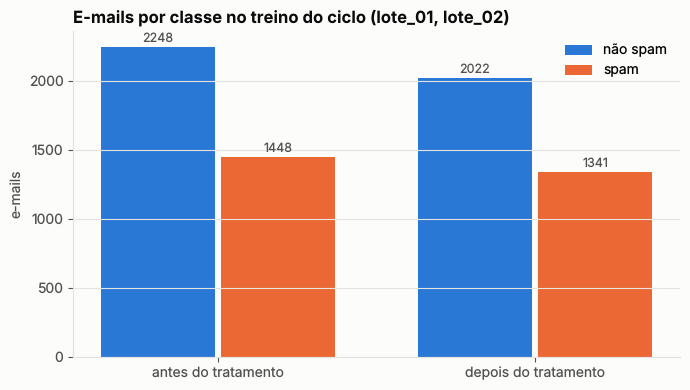

In [11]:
fig = graficos.grafico_classes(
    {"antes do tratamento": df_bruto[ALVO].value_counts(), "depois do tratamento": df_treino[ALVO].value_counts()},
    f"E-mails por classe no treino do ciclo ({', '.join(plano['lotes_ciclo'])})",
)
graficos.salvar_figura(fig, cfg, CYCLE_ID, "01_classes_antes_depois")

## 11. Resumo do ETL

Saídas gravadas para o relatório (pasta `reports/figuras/`):

| Arquivo | Conteúdo |
|---|---|
| `<cycle_id>_01_diagnostico_antes.csv` / `_depois.csv` | diagnóstico por coluna |
| `<cycle_id>_01_resumo_antes_depois.csv` | resumo do conjunto antes e depois |
| `<cycle_id>_01_outliers_iqr.csv` e `_01_outliers_taxa_spam.png` | análise de outliers |
| `<cycle_id>_01_tratamentos.csv` | tratamentos aplicados e justificativas |
| `<cycle_id>_01_verificacao_qualidade.csv` | regras de qualidade aprovadas |
| `<cycle_id>_01_classes_antes_depois.png` | distribuição das classes |

Próximo passo: **notebook 02**, votação de features.

In [12]:
print(f"Ciclo {CYCLE_ID} | {DATA_VERSION} | {len(df_treino)} linhas de treino | lote novo: {plano['lote_novo']}")

Ciclo 20261122T202358Z | lotes-01+02_h0ce6906487cc | 3363 linhas de treino | lote novo: None
